## APP URL and Github

Streamlit app:https://ind320application-knut.streamlit.app/    

Repository:https://github.com/Knutis1/IND320_Application

Video: https://nmbu.cloud.panopto.eu/Panopto/Pages/Viewer.aspx?id=028bbf36-2411-4d9b-97dc-b4e901304149

## Imports

In [1]:
import sys
sys.path.insert(0, "../modules")   # lets the notebook import our own modules

import pandas as pd
import matplotlib.pyplot as plt
from nve_api import fetch_reservoirs, fetch_areas, select_area, VALUE_COLS

## Areas covered by the API

In [2]:
# The API documents which areas exist: the country total, five elspot
# areas and the watercourse areas.
areas = fetch_areas()
areas

,navn,navn_langt,beskrivelse,omrType,omrnr
0,Norge,Norge,Hele landet,NO,0
1,NO 1,Elspotområde 1,Sørøst-Norge. Omfatter østlige del av Østlande...,EL,1
2,NO 2,Elspotområde 2,Sørvest-Norge. Omfatter mesteparten av Vestfol...,EL,2
3,NO 3,Elspotområde 3,Midt-Norge. Omfatter nordre og vestlige del av...,EL,3
4,NO 4,Elspotområde 4,Nord-Norge. Omfatter resten av Trøndelag og No...,EL,4
5,NO 5,Elspotområde 5,Vest-Norge. Omfatter midtre del av Vestland op...,EL,5
6,VASS1,Vassdragsområde 1,"Sørøst-Norge. Østlandet, Agder og deler av Rog...",VASS,1
7,VASS2,Vassdragsområde 2,Vest-Norge. Resten av Rogaland og Vestland.,VASS,2
8,VASS3,Vassdragsområde 3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørl...",VASS,3
9,VASS4,Vassdragsområde 4,Nord-Norge. Resten av Nordland og nordover.,VASS,4


Beskrive...

## Downloading the data from the API

In [3]:
# Replaces pd.read_csv("reservoirs.csv") from Part 1
df_raw = fetch_reservoirs()
print("Rows:", len(df_raw))
print("From:", df_raw["date"].min(), "to:", df_raw["date"].max())
df_raw.head()

Rows: 14922
From: 1995-01-08 00:00:00 to: 2026-10-11 00:00:00


,date,area_type,area_number,iso_year,iso_week,filling_level,capacity_TWh,stored_energy_TWh,next_publication_date,filling_level_prev_week,filling_level_change
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


## Selecting Norway total

In [4]:
# Every week appears once per area and the rows are unsorted,
# so filter to one area and sort before plotting.
df = select_area(df_raw, area_type="NO", area_number=0)
df.describe()

,filling_level,capacity_TWh,stored_energy_TWh,filling_level_prev_week,filling_level_change
count,1658.000000,1.658000e+03,1658.000000,1658.000000,1658.000000
mean,0.622169,8.743758e+01,54.400926,0.622206,-0.000037
std,0.195691,1.421514e-14,17.110790,0.195710,0.027673
min,0.180250,8.743758e+01,15.760602,0.180260,-0.144643
25%,0.461099,8.743758e+01,40.317419,0.461099,-0.022020
50%,0.647552,8.743758e+01,56.620398,0.647567,-0.005516
75%,0.788700,8.743758e+01,68.962040,0.788699,0.016301
max,0.966610,8.743758e+01,84.518060,0.966610,0.125774


## Plotting each column seperately (the same as in Part 1)

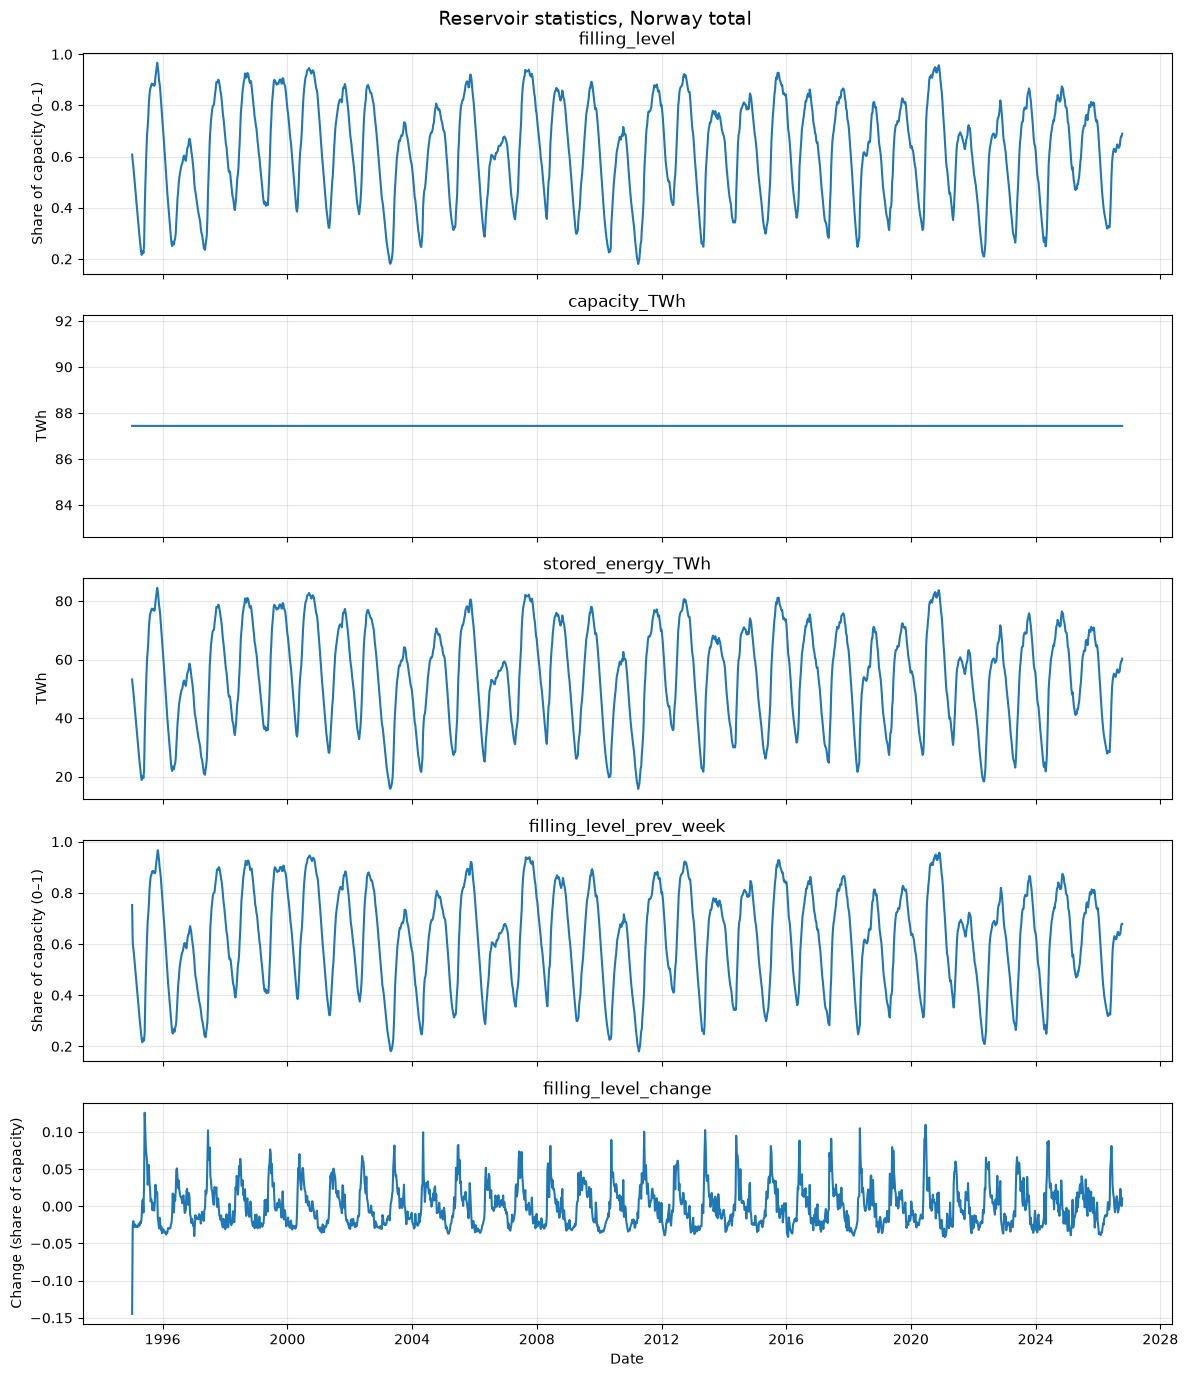

In [5]:
# Unit for each column, used as y-axis labels
units = {
    "filling_level": "Share of capacity (0–1)",
    "capacity_TWh": "TWh",
    "stored_energy_TWh": "TWh",
    "filling_level_prev_week": "Share of capacity (0–1)",
    "filling_level_change": "Change (share of capacity)",
}

# One subplot per column, sharing the time axis
fig, axes = plt.subplots(len(VALUE_COLS), 1, figsize=(12, 14), sharex=True)
for ax, col in zip(axes, VALUE_COLS):
    ax.plot(df.index, df[col])
    ax.set_title(col)
    ax.set_ylabel(units[col])
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Date")
fig.suptitle("Reservoir statistics, Norway total", fontsize=14)
plt.tight_layout()
plt.show()

## All columns plotted together (the same as in part 1)

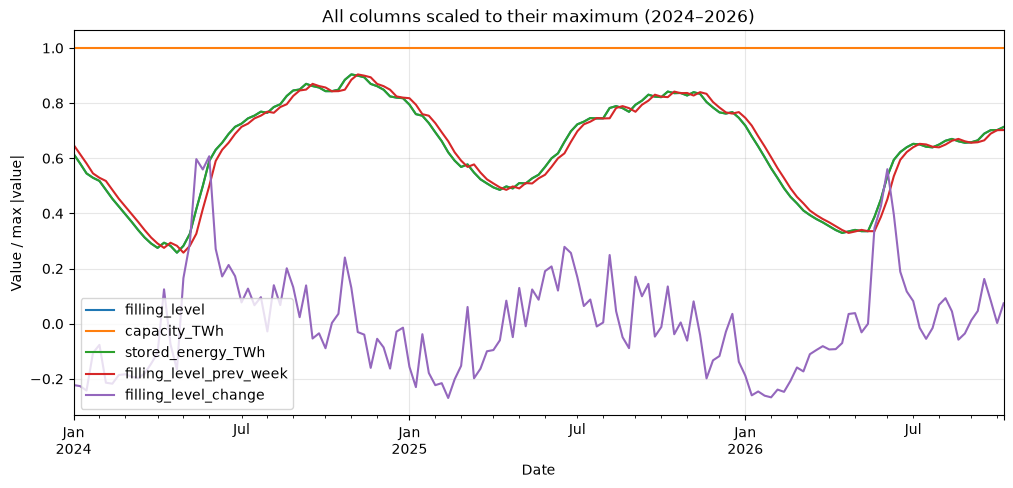

In [6]:
# Scaling each column by its largest absolute value -> all values inside [-1, 1]
df_scaled = df / df.abs().max()

# Plotting only the last 3 years so the lines are more readable
df_scaled.loc["2024":].plot(figsize=(12, 5))
plt.title("All columns scaled to their maximum (2024–2026)")
plt.xlabel("Date")
plt.ylabel("Value / max |value|")
plt.grid(alpha=0.3)
plt.legend(loc="lower left")
plt.show()

I used the same code as in part 1 to recreate the plots that I have been created by the data from the API, instead of the CSV file. This workd because df has the same shape as before. 

## SPARK

In [7]:
import sys
sys.path.insert(0, "../modules")   # from App/notebooks/ up to App/modules/
from spark_env import get_spark

spark = get_spark()
spark

JAVA_HOME   : C:\Program Files\Eclipse Adoptium\jdk-17.0.20.101-hotspot
HADOOP_HOME : C:\hadoop
Java        : openjdk version "17.0.20.1" 2026-08-18


## Cassandra keyspace and table

Creating the Cassandra schema

The keyspace and table were created with cqlsh inside the Cassandra container, because the Python cassandra-driver cannot be imported on Python 3.12 (its default connection class relied on asyncore, removed from the standard library in 3.12, and the libev C extension is not built on Windows). Spark communicates with Cassandra through the connector jar and does not use that driver, so nothing else in the project is affected.

CREATE KEYSPACE IF NOT EXISTS ind320
  WITH replication = {'class':'SimpleStrategy','replication_factor':1};

CREATE TABLE IF NOT EXISTS ind320.crossborder_flows (
    connection text, direction text, ts timestamp, flow_mw double,
    PRIMARY KEY ((connection, direction), ts));

The partition key (connection, direction) gives one partition per time series with rows ordered by time, which matches how both plots read the data

## Small ENTSO-E test first 

In [8]:
import pandas as pd
from entsoe_api import get_client, fetch_connection, CONNECTIONS

client = get_client()
test = fetch_connection(
    client, "NO2-DK1",
    start=pd.Timestamp("2026-01-01", tz="Europe/Oslo"),
    end=pd.Timestamp("2026-01-08", tz="Europe/Oslo"))

print(test.shape)
print(test.groupby("direction")["flow_mw"].describe())
test.head()

(1344, 4)
           count        mean         std  min  25%     50%          75%  \
direction                                                                 
export     672.0  671.869613  642.124444  0.0  0.0  543.44  1364.085000   
import     672.0  313.364938  556.598585  0.0  0.0    0.00   371.055818   

                  max  
direction              
export     1631.52000  
import     1605.54456  


,connection,direction,ts,flow_mw
0,NO2-DK1,export,2025-12-31 23:00:00,0.19
1,NO2-DK1,export,2025-12-31 23:15:00,0.00
2,NO2-DK1,export,2025-12-31 23:30:00,0.00
3,NO2-DK1,export,2025-12-31 23:45:00,0.00
4,NO2-DK1,export,2026-01-01 00:00:00,0.00


## The full download

In [9]:
from pathlib import Path

import pandas as pd
from entsoe_api import fetch_all

# The download takes a few minutes, so the result is cached on disk.
# A kernel restart (or the final Restart + Run All before exporting the PDF)
# then reuses the cached file instead of calling the API again.
CACHE = Path("flows_cache.parquet").resolve()

if CACHE.exists():
    flows = pd.read_parquet(CACHE)
    print("Loaded from cache:", len(flows), "rows")
else:
    flows = fetch_all(years=2)
    flows.to_parquet(CACHE, index=False)
    print("Downloaded and cached:", len(flows), "rows")

flows.groupby(["connection", "direction"]).size()


Loaded from cache: 345000 rows


connection  direction
NO1-SE3     export       44946
            import       44946
NO2-DK1     export       57474
            import       57474
NO2-NL      export       70080
            import       70080
dtype: int64

## Write to Cassandra with Spark

In [10]:
from pyspark.sql import functions as F

# Do not infer TIMESTAMP_NTZ when reading parquet ...
spark.conf.set("spark.sql.parquet.inferTimestampNTZ.enabled", "false")

sdf = spark.read.parquet(CACHE.as_uri())

# ... and cast explicitly as well, so the type is right on any Spark version.
# Cassandra needs 'timestamp', not 'timestamp_ntz'.
sdf = sdf.withColumn("ts", F.col("ts").cast("timestamp"))

print("Rows to write:", sdf.count())
sdf.printSchema()          # ts must say 'timestamp'


Rows to write: 345000
root
 |-- connection: string (nullable = true)
 |-- direction: string (nullable = true)
 |-- ts: timestamp (nullable = true)
 |-- flow_mw: double (nullable = true)



In [11]:
# Throttled write settings: small batches and few concurrent writes so the
# single-node Cassandra in Docker is not overwhelmed.
WRITE_OPTIONS = {
    "table": "crossborder_flows",
    "keyspace": "ind320",
    "spark.cassandra.output.concurrent.writes": "2",
    "spark.cassandra.output.batch.size.rows": "100",
    "spark.cassandra.output.throughputMBPerSec": "5",
    "spark.cassandra.connection.timeoutMS": "60000",
    "spark.cassandra.query.retry.count": "10",
}

connections = [row["connection"] for row in
               sdf.select("connection").distinct().collect()]

# One connection at a time: each job stays small, and a failure names the
# connection it happened on instead of losing the whole write.
for name in connections:
    chunk = sdf.filter(sdf.connection == name).repartition(2)
    print(f"writing {name}: {chunk.count()} rows ...", flush=True)
    (chunk.write
        .format("org.apache.spark.sql.cassandra")
        .options(**WRITE_OPTIONS)
        .mode("append")
        .save())
    print(f"{name} done", flush=True)

# Cassandra overwrites rows with the same primary key, so re-running this
# cell does not create duplicates.
print("All connections written to Cassandra")


writing NO2-NL: 140160 rows ...
NO2-NL done
writing NO2-DK1: 114948 rows ...
NO2-DK1 done
writing NO1-SE3: 89892 rows ...
NO1-SE3 done
All connections written to Cassandra


## Read back and aggregate with Spark

In [12]:
from pyspark.sql import functions as F

sdf_all = (spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(table="crossborder_flows", keyspace="ind320")
    .load())

print("Rows in Cassandra:", sdf_all.count())

# Yearly totals per connection and direction -> the pie chart data
yearly = (sdf_all
    .withColumn("year", F.year("ts"))
    .groupBy("connection", "direction", "year")
    .agg(F.sum("flow_mw").alias("total_mwh"))
    .toPandas())
yearly

Rows in Cassandra: 345006


,connection,direction,year,total_mwh
0,NO1-SE3,import,2025,1.207928e+07
1,NO1-SE3,import,2024,1.603768e+06
2,NO1-SE3,import,2026,1.711256e+07
3,NO2-NL,export,2025,1.116404e+07
4,NO2-NL,export,2024,3.815906e+06
5,NO2-NL,export,2026,3.176693e+06
6,NO2-DK1,export,2025,2.482030e+07
7,NO2-DK1,export,2026,1.508373e+07
8,NO2-DK1,export,2024,2.047821e+06
9,NO1-SE3,export,2026,4.781288e+06


## Pie chart

   connection direction  year     total_mwh
6     NO2-DK1    export  2025  2.482030e+07
17    NO2-DK1    import  2025  4.140667e+06


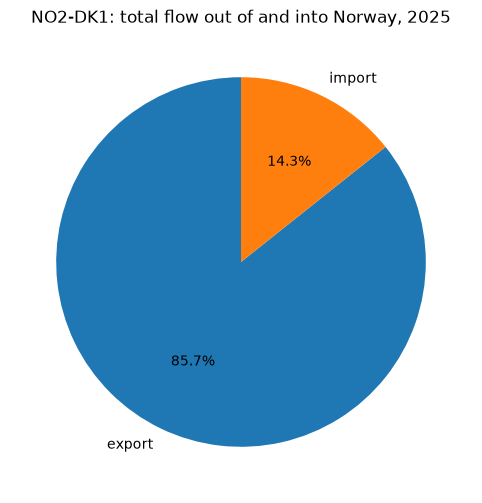

In [13]:
import matplotlib.pyplot as plt

conn, year = "NO2-DK1", 2025

subset = yearly[(yearly["connection"] == conn) & (yearly["year"] == year)]
print(subset)                      # <- what is actually being plotted

plt.figure(figsize=(6, 6))
plt.pie(subset["total_mwh"], labels=subset["direction"],
        autopct="%1.1f%%", startangle=90)
plt.title(f"{conn}: total flow out of and into Norway, {year}")
plt.show()

## Line plot, first month

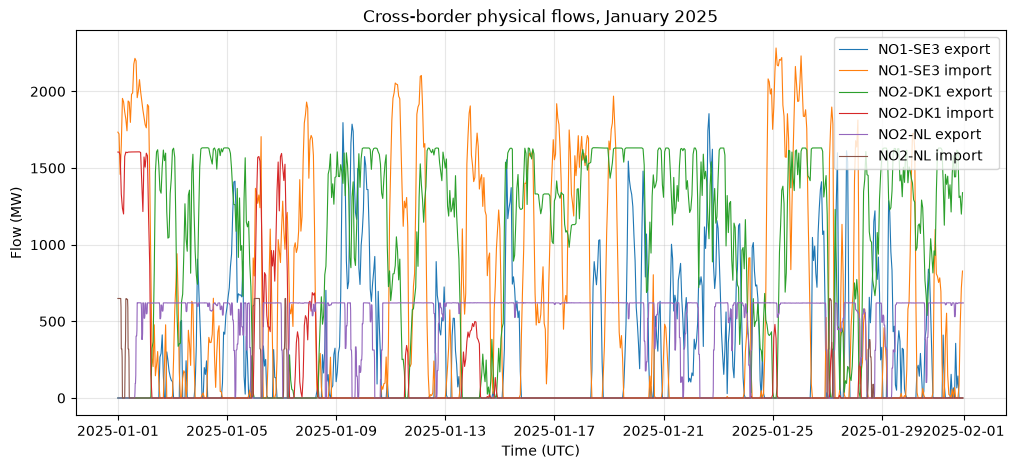

In [14]:
month = (sdf_all
    .filter((F.year("ts") == 2025) & (F.month("ts") == 1))
    .toPandas()
    .sort_values("ts"))

plt.figure(figsize=(12, 5))
for (c, d), group in month.groupby(["connection", "direction"]):
    plt.plot(group["ts"], group["flow_mw"], label=f"{c} {d}", linewidth=0.8)

plt.title("Cross-border physical flows, January 2025")
plt.xlabel("Time (UTC)")
plt.ylabel("Flow (MW)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Into MongoDB

In [ ]:
import os
from pymongo import MongoClient
from dotenv import load_dotenv

load_dotenv()
db = MongoClient(os.environ["MONGO_URI"])["ind320"]

# Yearly totals -> the pie chart on the app
db.flows_yearly.delete_many({})
db.flows_yearly.insert_many(yearly.to_dict("records"))

# Hourly rows -> the line plot on the app
hourly = sdf_all.toPandas()
db.flows_hourly.delete_many({})
for i in range(0, len(hourly), 5000):
    db.flows_hourly.insert_many(hourly.iloc[i:i + 5000].to_dict("records"))

db.flows_hourly.create_index([("connection", 1), ("direction", 1), ("ts", 1)])

print("flows_yearly:", db.flows_yearly.count_documents({}))
print("flows_hourly:", db.flows_hourly.count_documents({}))

## LOG AND AI USAGE

Part 2 turned the project from a single CSV file into a small pipeline: two APIs at one end, two databases in the middle, and the Streamlit app at the other end. The plotting was mostly reused from Part 1. Almost all of the time went into getting the pieces to talk to each other.

Replacing the CSV with the NVE API was the easy half. The data loading in Part 1 was already inside one function, so only that function had to change and the pages kept working. I split the code into one module that calls the API and a thin module that adds Streamlit caching on top, so the notebook can use the same functions without importing Streamlit. The API has no date parameters and always returns the full history, so the download interval chosen in the app is applied right after the call.

The ENTSO-E part was harder. Physical flow is reported separately in each direction, so every connection needs two queries, and the timestamps arrive in local time and must be converted to UTC before being stored. That is the same lesson as the date columns in Part 1, in a new place. The download of two years for three connections took around fifteen minutes, so I cache the result to a parquet file; otherwise every kernel restart would mean downloading everything again.

The local setup caused the most trouble. Cassandra runs in Docker because there is no supported Windows build, and Spark needed a specific Java version and the winutils helper before it would start at all. The Python Cassandra driver could not even be imported on Python 3.12, because its default connection class uses a module that was removed from the standard library, so I created the keyspace and table with cqlsh inside the container instead. Spark does not use that driver, so nothing else was affected.

Writing to Cassandra failed several times before it worked. First, converting the pandas DataFrame with createDataFrame pushed every row through Python worker processes, which crash on Windows; writing to parquet and letting Spark read that keeps everything on the JVM. Then the connector rejected the timestamps, because parquet has no timezone and Spark reads such columns as TIMESTAMP_NTZ, which the connector cannot convert, so the column has to be cast back to a normal timestamp. Finally, writing 345 000 rows in one job timed out against a single-node Cassandra, so the write is throttled and done one connection at a time.

In Cassandra I partition on connection and direction, which gives one partition per time series with rows ordered by time. Spark does the aggregation and only the small result goes to MongoDB, which is what the deployed app reads, since it cannot reach my local Cassandra. The last obstacle was the MongoDB connection string: it must be quoted in secrets.toml but not in .env, and the hostname is the one Atlas issues, not the cluster name I had typed. I wasted a lot of time just getting the MongoDB connected...

As for the AI I am still using Claude to help me. Some places, especially when it comes to cassandra/spark etc, where it doesn't work like I think it should, it has explained it in text what it does and why it does it. This helps to understand what it means to the code and the significance. 